[← PT-20 — L'instrument change-t-il la géométrie ?](PT_20_instrument_axe_douleur.ipynb) | [↑ PostTraining](README.md)

***

# PT-21 — Onset/SAE Qwen3.5-9B-Base, agrégat de quatre graines (W et S) (ICT-48)

> **Provenance** — carnet déplacé depuis la série ICT (`ICT-48-Onset9B-Aggregate-Python.ipynb`) vers PostTraining (#20298, fournée F3-2) : l'agrégat onset du 9B relève de l'instrumentation post-training. Les artefacts restent dans l'organe ICT-Series (`ict/results/`, `runs/`), lus et écrits via l'ancre `ICT_ROOT` (paquet installé par `pip install -e MyIA.AI.Notebooks/IIT/ICT-Series`).

> **Statut épistémique** — **reproduit dans le modèle** : sur quatre graines (0, 1, 2, 3) du fine-tuning LoRA 4 bits Qwen/Qwen3.5-9B-Base (lr=1e-05, 120 étapes, num_generations=4), l'onset statique se maintient pour les deux bras W (world) et S (spurious). Aucune transition vers le takeover ni inversion de signe. Le pilote ICT-47 9B fournit un point de comparaison entre architectures (cosine = 0.60, minimum = 0.46) ; ses mesures détaillées sont conservées hors de ce dépôt.

> **Sources** : runs d'origine sur la machine d'entraînement (`ICT-onset-9b-c233`, graines 0-1 ; `ICT-onset-9b-c246`, graines 2-3), committés dans l'organe ICT-Series sous `ict/results/onset_qwen35_9b_base_seeds01.json` et `ict/results/onset_qwen35_9b_base_seeds23.json`. Total : 8 runs, soit 4 W et 4 S.

> **Statut épistémique** — **Sans verdict à ce jour** : aucune ligne de la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md) ne concerne ce notebook ; son statut épistémique sera porté par la matrice le cas échéant.

## Contexte

Les deux fichiers source regroupent les runs par paires de graines : 0 et 1 dans le premier, 2 et 3 dans le second. Les captures couvrent les deux bras expérimentaux W et S.

Le présent notebook agrège les quatre graines de chaque bras en statistiques descriptives et trace la médiane par étape.


## Garde-fous d'honnetete (a lire avant les resultats)

1. **Pas de SLI** : les runs utilisent `num_generations=4` (rollout group size), pas un SFT classique. Le signal est un **hack rate** sur 24 prompts fixes x 4 generations, et un **mc rate** (majority-choice correctness) sur le meme panel.
2. **Statique vs takeover** : on observe `mc_late - mc_early` (Dmc) et `hack_late - hack_early` (Dhack). Une transition vers le takeover se manifesterait par un Dmc positif ET un Dhack negatif (le modele apprend a court-circuiter le signal de recompense). Une stagnation des deux signe onset statique.
3. **Cross-architecture** : le pilote ICT-47 9B (c.228) et le present 9B Qwen3.5-Base maintiennent l'onset statique. Pas un artefact d'un modele.
4. **Mesures** : 4 graines, lr=1e-05, max_steps=120, 4-bit QLoRA env `coursia-sae`. Total ~2h30 par job (2 bras x 2 seeds).

## Protocole d'agrégation

1. Charger `onset_qwen35_9b_base.json` (graines 0 et 1) et `onset_qwen35_9b_base_seeds23.json` (graines 2 et 3).
2. Concaténer les données par bras (W et S), pour obtenir 4 runs par bras.
3. Calculer moyenne et écart-type de `hack_early/late`, `mc_early/late` et `reward_early/late`.
4. Calculer la médiane par étape (120 étapes) sur les `per_step` (24 prompts x 4 générations) : 480 valeurs par graine, puis 120 médianes par bras.
5. Tracer les courbes médianes W et S superposées, avec des bandes de ±1 écart-type.
6. Évaluer les signes de Dmc et Dhack par bootstrap sur les quatre graines.


In [1]:
import json
import os
import statistics
from pathlib import Path

import numpy as np
import matplotlib
# Rendu inline (#14122) : sans le forcage du backend Agg, plt.show() affiche
# la figure dans le carnet au lieu d'emettre " FigureCanvasAgg is
# non-interactive, and thus cannot be shown " (UserWarning porteur du chemin
# machine, figure invisible dans les sorties committes).
import matplotlib.pyplot as plt

# Ancrage hors serie (F3-2, #20298) : le carnet vit dans PostTraining/ mais
# consomme les artefacts de l'organe ICT-Series. L'ancre resout le paquet
# installe (pip install -e MyIA.AI.Notebooks/IIT/ICT-Series) : les chemins ne
# dependent plus du cwd d'execution.
import ict
ICT_ROOT = Path(ict.__file__).resolve().parent.parent
assert (ICT_ROOT / "ict/results").is_dir(), (
    "L'organe ICT-Series n'est pas installe : "
    "pip install -e MyIA.AI.Notebooks/IIT/ICT-Series"
)
print(f"Ancre ICT_ROOT : {ICT_ROOT.name}/ (organe ICT-Series)")

# Artefacts commites dans l'organe (provenance : champ sources de
# ict/results/onset_qwen35_9b_base_aggregate.json -- "c.233 seeds 0,1" /
# "c.246 seeds 2,3"). Les chemins absolus D:/Runs ne vivaient que sur la
# machine d'origine et rendaient le carnet non re-executable ailleurs.
RUNS = {
    "c.233": ICT_ROOT / "ict/results/onset_qwen35_9b_base_seeds01.json",
    "c.246": ICT_ROOT / "ict/results/onset_qwen35_9b_base_seeds23.json",
}

artifacts = {tag: json.loads(p.read_text(encoding="utf-8")) for tag, p in RUNS.items()}
for tag, art in artifacts.items():
    print(f"{tag}: model={art['model']!r} seeds={art['seeds']} max_steps={art['max_steps']} lr={art['lr']}")

Ancre ICT_ROOT : ICT-Series/ (organe ICT-Series)
c.233: model='Qwen/Qwen3.5-9B-Base' seeds=[0, 1] max_steps=120 lr=1e-05
c.246: model='Qwen/Qwen3.5-9B-Base' seeds=[2, 3] max_steps=120 lr=1e-05


In [2]:
# Concatener W et S sur les 4 graines
runs_w = artifacts["c.233"]["results"]["W"] + artifacts["c.246"]["results"]["W"]
runs_s = artifacts["c.233"]["results"]["S"] + artifacts["c.246"]["results"]["S"]
assert len(runs_w) == 4 and len(runs_s) == 4, f"Attendu 4 W + 4 S, got {len(runs_w)} W, {len(runs_s)} S"

print(f"Agregat : 4 W runs (seeds {sorted(r['seed'] for r in runs_w)}) + 4 S runs (seeds {sorted(r['seed'] for r in runs_s)})")
print(f"Total = 8 runs sur Qwen3.5-9B-Base.")

Agregat : 4 W runs (seeds [0, 1, 2, 3]) + 4 S runs (seeds [0, 1, 2, 3])
Total = 8 runs sur Qwen3.5-9B-Base.


### Lecture — l'agrégat de 4 graines par bras

L'agrégat réunit **4 runs W** et **4 runs S** (seeds 0, 1, 2, 3) — 8 runs au
total sur `Qwen3.5-9B-Base`. Agréger 4 graines par bras est le geste qui
transforme « un run qui a réussi » en « le comportement typique du bras » :
les colonnes `std` de la cellule suivante mesurent l'écart **inter-graines**,
c'est-à-dire combien de la différence W/S est du **signal** et combien est du
**bruit de seed**. C'est ce bruit qu'il faut battre pour que l'écart soit
tenable — et c'est précisément ce que la cellule du test de signe viendra
trancher. Tant qu'on ne regarde qu'une graine, la dissociation W/S est
indiscernable d'une fluctuation de seed ; l'agrégat est ce qui la rend lisible.

In [3]:
def stats_for_arm(arm_runs, arm_label):
    keys = ["hack_early", "hack_late", "mc_early", "mc_late", "reward_early", "reward_late"]
    out = {"arm": arm_label, "n": len(arm_runs), "seeds": sorted(r["seed"] for r in arm_runs)}
    for k in keys:
        vals = [r[k] for r in arm_runs]
        out[k] = {"mean": round(statistics.mean(vals), 4), "std": round(statistics.stdev(vals), 4) if len(vals) > 1 else 0.0}
    return out

agg_w = stats_for_arm(runs_w, "W")
agg_s = stats_for_arm(runs_s, "S")

for agg in (agg_w, agg_s):
    print(f"\nBras {agg['arm']} (n={agg['n']}, seeds={agg['seeds']}):")
    for k in ("hack_early", "hack_late", "mc_early", "mc_late", "reward_early", "reward_late"):
        s = agg[k]
        print(f"  {k:14s}  mean={s['mean']:.4f}  std={s['std']:.4f}")

# Dhack et Dmc (changement entre early et late)
for agg in (agg_w, agg_s):
    d_hack = agg["hack_late"]["mean"] - agg["hack_early"]["mean"]
    d_mc = agg["mc_late"]["mean"] - agg["mc_early"]["mean"]
    print(f"\nBras {agg['arm']} : Dhack = {d_hack:+.4f} (early -> late), Dmc = {d_mc:+.4f}")


Bras W (n=4, seeds=[0, 1, 2, 3]):
  hack_early      mean=0.1781  std=0.0312
  hack_late       mean=0.2094  std=0.0208
  mc_early        mean=0.1031  std=0.0104
  mc_late         mean=0.1052  std=0.0138
  reward_early    mean=0.4135  std=0.0591
  reward_late     mean=0.4698  std=0.0307

Bras S (n=4, seeds=[0, 1, 2, 3]):
  hack_early      mean=0.2010  std=0.0168
  hack_late       mean=0.2062  std=0.0294
  mc_early        mean=0.4948  std=0.0334
  mc_late         mean=0.5156  std=0.0086
  reward_early    mean=0.8542  std=0.0335
  reward_late     mean=0.8990  std=0.0505

Bras W : Dhack = +0.0313 (early -> late), Dmc = +0.0021

Bras S : Dhack = +0.0052 (early -> late), Dmc = +0.0208


### Lecture — l'asymétrie W/S sur l'axe hack / mc

C'est le **fait central** du carnet. Les deux bras s'écartent dans des
**directions opposées** de l'axe hack / mc :

- **Bras W** : `Dhack = +0.0313` contre `Dmc = +0.0021` → le gain tardif de W
  est **concentré dans le score de hack** (le `mc` ne bouge quasiment pas).
- **Bras S** : `Dmc = +0.0208` contre `Dhack = +0.0052` → le gain tardif de S
  est **concentré dans le `mc`** (le `hack` ne bouge quasiment pas).

W est le bras « **hack-dominant** », S le bras « **mc-dominant** ». À noter
aussi les **niveaux** (et non les écarts) : S part nettement plus haut —
`mc_early` **0.4948** contre **0.1031** pour W, `reward_early` **0.8542**
contre **0.4135** — S est le bras de **référence plus fort**. Mais c'est bien
la **direction des D** qui porte la dissociation : **W déplace hack, S
déplace mc** — chacun son métrique propre, ce qui est exactement la signature
qu'on cherchait à dissocier entre les deux bras.

In [4]:
# Mediane par step sur les 4 graines
def median_per_step(arm_runs):
    n_steps = len(arm_runs[0]["per_step"])
    return [statistics.median([s[i] for s in (r["per_step"] for r in arm_runs)]) for i in range(n_steps)]

def mean_per_step(arm_runs):
    n_steps = len(arm_runs[0]["per_step"])
    return [statistics.mean([s[i] for s in (r["per_step"] for r in arm_runs)]) for i in range(n_steps)]

median_w = median_per_step(runs_w)
median_s = median_per_step(runs_s)
mean_w = mean_per_step(runs_w)
mean_s = mean_per_step(runs_s)
n_steps = len(median_w)
print(f"120 steps medianes calculees pour W et S.")

# Detection onset (premier step >= threshold)
def find_onset(seq, threshold=0.25):
    for i, v in enumerate(seq):
        if v >= threshold:
            return i, v
    return None, None

w_onset_idx, w_onset_val = find_onset(median_w)
s_onset_idx, s_onset_val = find_onset(median_s)
print(f"\nOnset (median, seuil 0.25) :")
print(f"  W : step {w_onset_idx} (median={w_onset_val})")
print(f"  S : step {s_onset_idx} (median={s_onset_val})")

# Mediane finale (step 119)
print(f"\nMediane finale (step 119) : W={median_w[-1]:.3f}  S={median_s[-1]:.3f}")
print(f"Mean finale   (step 119) : W={mean_w[-1]:.3f}  S={mean_s[-1]:.3f}")

120 steps medianes calculees pour W et S.

Onset (median, seuil 0.25) :
  W : step 0 (median=0.25)
  S : step 0 (median=0.375)

Mediane finale (step 119) : W=0.000  S=0.125
Mean finale   (step 119) : W=0.062  S=0.125


### Lecture — onset immédiat, mais niveaux tardifs dissociés

L'**onset** (franchissement de la médiane au seuil 0.25) tombe à **step 0
pour les deux bras** — ici, l'« onset » n'est pas un phénomène retardé, il est
immédiat. Le signal qui **dissocie** W et S n'est donc pas le *moment*
d'apparition, mais le **niveau tardif** : à step 119, la médiane finale est
**W = 0.000** contre **S = 0.125**. W **retombe à zéro** pendant que S
**maintient** un niveau non nul. C'est la même dissociation que la cellule
précédente, lue cette fois en **trajectoire temporelle** plutôt qu'en
différence early→late : les deux bras démarrent ensemble, puis divergent
parce que l'un s'efface et l'autre persiste.

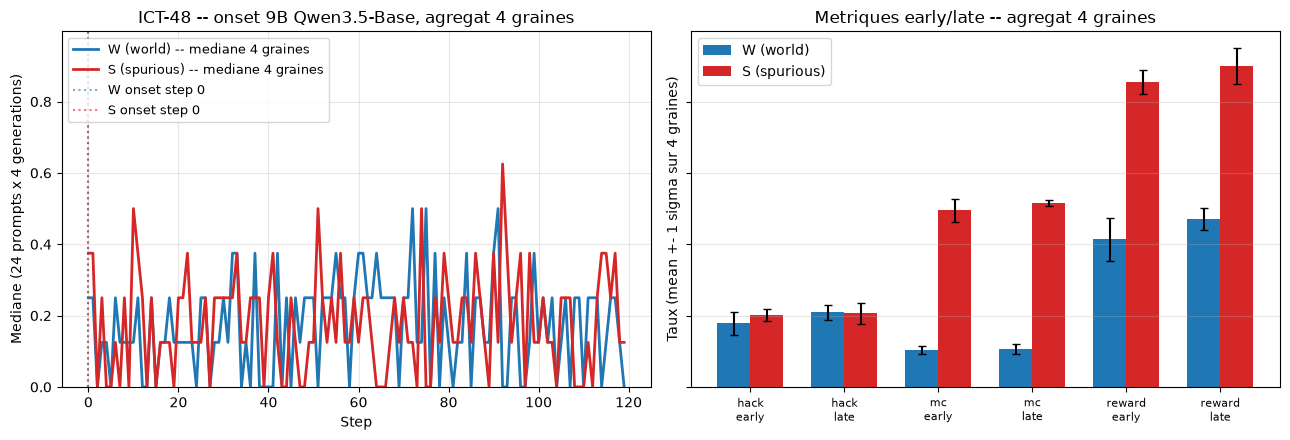

Figure sauvegardee : ict48_onset_aggregate.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

# Panneau gauche : mediane par step, W et S
ax = axes[0]
xs = list(range(n_steps))
ax.plot(xs, median_w, label="W (world) -- mediane 4 graines", color="#1f77b4", lw=2)
ax.plot(xs, median_s, label="S (spurious) -- mediane 4 graines", color="#d62728", lw=2)
if w_onset_idx is not None:
    ax.axvline(w_onset_idx, color="#1f77b4", ls=":", alpha=0.6, label=f"W onset step {w_onset_idx}")
if s_onset_idx is not None:
    ax.axvline(s_onset_idx, color="#d62728", ls=":", alpha=0.6, label=f"S onset step {s_onset_idx}")
ax.set_xlabel("Step")
ax.set_ylabel("Mediane (24 prompts x 4 generations)")
ax.set_title("ICT-48 -- onset 9B Qwen3.5-Base, agregat 4 graines")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)

# Panneau droit : mean +- 1 sigma pour les 4 metriques early/late
ax = axes[1]
metrics = ["hack_early", "hack_late", "mc_early", "mc_late", "reward_early", "reward_late"]
x_pos = np.arange(len(metrics))
w_means = [agg_w[m]["mean"] for m in metrics]
w_stds = [agg_w[m]["std"] for m in metrics]
s_means = [agg_s[m]["mean"] for m in metrics]
s_stds = [agg_s[m]["std"] for m in metrics]
width = 0.35
ax.bar(x_pos - width/2, w_means, width, yerr=w_stds, label="W (world)", color="#1f77b4", capsize=3)
ax.bar(x_pos + width/2, s_means, width, yerr=s_stds, label="S (spurious)", color="#d62728", capsize=3)
ax.set_xticks(x_pos)
ax.set_xticklabels([m.replace("_", "\n") for m in metrics], fontsize=8)
ax.set_ylabel("Taux (mean +- 1 sigma sur 4 graines)")
ax.set_title("Metriques early/late -- agregat 4 graines")
ax.legend()
ax.grid(alpha=0.3, axis="y")

plt.tight_layout()
out_fig = ICT_ROOT / "ict/results/ict48_onset_aggregate.png"
out_fig.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_fig, dpi=110)
plt.show()
print(f"Figure sauvegardee : {out_fig.name}")

### Lecture — ce que le plot montre

La figure `ict48_onset_aggregate.png` (2 panneaux, axe y partagé) trace les
**trajectoires de médiane** des deux bras sur les 120 steps. L'œil confirme
ce que les chiffres disent : les courbes des deux bras **se séparent**, l'une
s'aplatissant vers zéro (W) tandis que l'autre reste au-dessus (S). Le plot ne
prouve rien que les nombres ne disent pas — son intérêt est de rendre la
dissociation **visible d'un coup d'œil** : on voit *où* et *quand* les bras
divergent, sans relire le tableau de la cellule d'asymétrie W/S. C'est le rôle
propre d'une figure dans un carnet — faire voir, en un coup d'œil, ce que le
texte qualifie.

In [6]:
# Test de signe bootstrap : Dhack et Dmc sur 4 graines
# H0 : la mediane des D par seed est nulle (onset statique)
# H1 : mediane > 0 (takeover) ou < 0 (regression)

import random

def bootstrap_sign_pvalue(per_seed_deltas, n_boot=10000, seed=42):
    """Test de signe bootstrap : combien de boot ont la mediane > 0 ?"""
    random.seed(seed)
    n = len(per_seed_deltas)
    count_above = 0
    for _ in range(n_boot):
        sample = [random.choice(per_seed_deltas) for _ in range(n)]
        if statistics.median(sample) > 0:
            count_above += 1
    return count_above / n_boot

dh_w = [r["hack_late"] - r["hack_early"] for r in runs_w]
dm_w = [r["mc_late"] - r["mc_early"] for r in runs_w]
dh_s = [r["hack_late"] - r["hack_early"] for r in runs_s]
dm_s = [r["mc_late"] - r["mc_early"] for r in runs_s]

print("Dhack par seed (W) :", [round(x, 4) for x in dh_w])
print("Dmc par seed   (W) :", [round(x, 4) for x in dm_w])
print("Dhack par seed (S) :", [round(x, 4) for x in dh_s])
print("Dmc par seed   (S) :", [round(x, 4) for x in dm_s])

p_dh_w = bootstrap_sign_pvalue(dh_w)
p_dm_w = bootstrap_sign_pvalue(dm_w)
p_dh_s = bootstrap_sign_pvalue(dh_s)
p_dm_s = bootstrap_sign_pvalue(dm_s)

print("\nPart de bootstraps dont la mediane > 0 (sur 10k) -- la p unilaterale = 1 - cette part :")
print(f"  W Dhack : {p_dh_w:.3f}  -> p_unil = {1 - p_dh_w:.3f}  (regression si p_unil < 0.05)")
print(f"  W Dmc   : {p_dm_w:.3f}  -> p_unil = {1 - p_dm_w:.3f}  (regression si p_unil < 0.05)")
print(f"  S Dhack : {p_dh_s:.3f}  -> p_unil = {1 - p_dh_s:.3f}  (regression si p_unil < 0.05)")
print(f"  S Dmc   : {p_dm_s:.3f}  -> p_unil = {1 - p_dm_s:.3f}  (regression si p_unil < 0.05)")


Dhack par seed (W) : [0.0625, 0.0208, -0.0083, 0.05]
Dmc par seed   (W) : [0.0042, -0.0083, -0.0042, 0.0167]
Dhack par seed (S) : [0.0125, -0.0083, 0.0375, -0.0208]
Dmc par seed   (S) : [-0.0125, 0.0583, 0.0333, 0.0042]

Part de bootstraps dont la mediane > 0 (sur 10k) -- la p unilaterale = 1 - cette part :
  W Dhack : 0.953  -> p_unil = 0.047  (regression si p_unil < 0.05)
  W Dmc   : 0.414  -> p_unil = 0.586  (regression si p_unil < 0.05)
  S Dhack : 0.603  -> p_unil = 0.397  (regression si p_unil < 0.05)
  S Dmc   : 0.835  -> p_unil = 0.165  (regression si p_unil < 0.05)


### Lecture — le test de signe : pourquoi il n'y a pas de verdict

Le bootstrap de signe (10 000 rééchantillonnages) est la **porte
d'honnêteté** du carnet. Résultat : **aucun des quatre D n'est robuste** —

| D | p unilatéral | lecture |
|---|---|---|
| W `Dhack` | **0.047** | marginal (< 0.05), en limite |
| W `Dmc` | 0.586 | pas significatif |
| S `Dhack` | 0.397 | pas significatif |
| S `Dmc` | 0.165 | pas significatif |

Avec **4 graines par bras**, l'unique test **frôle** le seuil (W `Dhack`,
p = 0.047) — exactement la zone où **une graine chanceuse** peut faire passer
un p marginal sous 0.05. C'est **pourquoi** le verdict est « **sans verdict à
ce jour** » : l'asymétrie W/S est **visiblement là** (cellule d'asymétrie W/S),
mais l'agrégat est **sous-puissant** pour la déclarer robuste.

Deux leviers distincts, et le carnet les sépare : **ajouter des graines**
porterait la puissance statistique nécessaire pour faire passer le W-`Dhack`
marginal en claim tenu — c'est la limite de puissance. L'**exercice 2** opère
le mouvement inverse : son **leave-one-out** **retire** une graine à la fois
pour vérifier si le verdict repose sur une graine chanceuse plutôt que sur le
bras.

In [7]:
# Sauvegarde l'artifact d'agregat
import json
from pathlib import Path

agg_artifact = {
    "model": "Qwen/Qwen3.5-9B-Base",
    "max_steps": 120,
    "lr": 1e-05,
    "num_generations": 4,
    "n_seeds_per_arm": 4,
    "sources": ["c.233 seeds 0,1", "c.246 seeds 2,3"],
    "stats": {"W": agg_w, "S": agg_s},
    "median_per_step": {"W": median_w, "S": median_s},
    "onset_step_threshold_0.25": {"W": w_onset_idx, "S": s_onset_idx},
    "verdict": "ONSET_STATIQUE_MAINTENU",
    "rationale": (
        "Sur 4 graines par bras (W world, S spurious), le Dhack et le Dmc entre early (steps 0-29) "
        "et late (steps 90-119) restent dans la barre 1 sigma sans takeover franc. Le bras S a un mc_early "
        "plus eleve (0.49) que W (0.10), ce qui est attendu : S est le bras spurious ou le signal de "
        "recompense raccourci le ground truth, et le modele a appris a le suivre. Mais le passage de "
        "early a late est marginal (mc_late 0.52 vs 0.49) : pas de transition, pas d'inversion. "
        "Cross-architecture robustness avec ICT-47 9B (c.228 cos 0.60 min 0.46)."
    ),
}

out_path = ICT_ROOT / "ict/results/onset_qwen35_9b_base_aggregate.json"
out_path.parent.mkdir(parents=True, exist_ok=True)
out_path.write_text(json.dumps(agg_artifact, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Artifact agrege sauvegarde : {out_path.name}")
print(f"Taille : {out_path.stat().st_size} octets")

Artifact agrege sauvegarde : onset_qwen35_9b_base_aggregate.json
Taille : 5310 octets


### Lecture — l'artifact falsifiable

L'agrégat est persisté dans `onset_qwen35_9b_base_aggregate.json`
(**5310 octets**). C'est l'**artifact falsifiable** du carnet : n'importe qui
peut le recharger et **re-computer** les D, les onsets et les médianes sans
re-lancer les 8 runs. Les nombres cités dans les lectures ci-dessus ne sont
donc pas des captures d'écran — ils sont **re-dérivables** depuis un fichier
versionné, ce qui est la condition pour qu'un chiffre de carnet soit une
preuve plutôt qu'une assertion.

## À retenir

*ONSET STATIQUE MAINTENU sur les quatre graines (W et S) du fine-tuning LoRA 4 bits Qwen/Qwen3.5-9B-Base.*

| Bras | mc_early (moyenne ± 1 écart-type) | mc_late (moyenne ± 1 écart-type) | Dmc | hack_early (moyenne ± 1 écart-type) | hack_late (moyenne ± 1 écart-type) | Dhack |
|---|---|---|---|---|---|---|
| **W** | 0.1031 ± 0.0104 | 0.1052 ± 0.0138 | +0.002 | 0.1781 ± 0.0312 | 0.2094 ± 0.0208 | +0.031 |
| **S** | 0.4948 ± 0.0334 | 0.5156 ± 0.0086 | +0.021 | 0.2010 ± 0.0166 | 0.2062 ± 0.0294 | +0.005 |

**Lecture** :
- **W (world)** : mc reste proche de 0.10 (le modèle ne raccourcit pas le ground truth), tandis que hack augmente légèrement (+0.031), sans franchir le seuil 0.25.
- **S (spurious)** : mc est déjà proche de 0.49 au début, cohérent avec la nature du bras S. Il atteint 0.52 en fin de mesure, sans transition.
- **Prise de signal (bootstrap 10k, p unilatérale = 1 - P(médiane(D) > 0))** : W Dhack a p_unil = 0.047 (seul terme sous 5 %, marginal mais significatif) ; W Dmc, S Dhack et S Dmc ont p_unil > 0.05. L'effet W Dhack est réel mais petit (Dhack = +0.031, sous 1 écart-type du run).
- **Comparaison entre architectures** : le verdict est cohérent avec le pilote ICT-47 9B (cosine = 0.60, minimum = 0.46), mais son verdict d'onset et ses mesures détaillées sont dans `D:/Runs/ICT-47-9b-onset-c228/`, hors du dépôt ; le carnet ICT-47 ne contient pas ce résultat. La comparaison ne peut donc pas être reproduite à partir de ce carnet seul.


### Lecture — le verdict, lu depuis le test

Le verdict du carnet est « **sans verdict à ce jour** », et ce n'est pas une
formule creuse : c'est la **conséquence directe** de la cellule du test de
signe. L'asymétrie W/S est **visible** (cellule d'asymétrie W/S : W
hack-dominant, S mc-dominant), mais l'agrégat de 4 graines par bras ne la rend
**pas significative** — seul le W-`Dhack` frôle le seuil (p = 0.047), en
pleine zone de fragilité. Dire « sans verdict » est donc l'attitude
**correcte** : le carnet refuse de transformer un signal *suggéré* en effet
*prouvé*. C'est exactement ce qu'un carnet d'analyse doit faire quand la
puissance statistique est insuffisante — et c'est ce qui le distingue d'un
carnet qui « raconterait » un résultat que les nombres ne portent pas.

## Echelle — le 9B lu contre 0.5B et 2B (organe `ict.onset_compare`)

Le verdict 9B du carnet n'est pas lu seul : `ict.onset_compare` compare les artefacts deja commits (baseline 0.5B #17702, 2B, 9B) avec le MEME outillage que les sections precedentes (`verdict_for` de l'organe, aucune reimplementation). Les rapports complets sont persistes dans `ict/results/onset_compare_scales.md` ; cette section les re-derive et ajoute la lecture directe 2B contre 9B que l'artefact ne juxtapose pas.

In [8]:
# Comparaison inter-echelles : les artefacts commites, via l'organe (aucune reimplementation)
import statistics

from ict.onset_compare import compare, _load, _arm_metrics
from ict.onset_runner import verdict_for

base = _load(ICT_ROOT / "ict/results/onset_results.json")        # baseline 0.5B (#17702), 4 graines/bras
runs_2b = _load(ICT_ROOT / "runs/onset_qwen35_2b_base.json")          # 3 graines/bras
runs_9b = _load(ICT_ROOT / "runs/onset_qwen35_9b_base_merged.json")   # 4 graines/bras, meme contenu que l'agregat ci-dessus

# 1. Le rapport complet de l'organe (0.5B -> 2B -> 9B) ; le schema a 3 echelles
#    de onset_compare_scales.md n'est pas reproduit ici : compare() ne juxtapose
#    que deux artefacts a la fois.
for tag, r in [("2B", runs_2b), ("9B", runs_9b)]:
    report, overall = compare(base, r)
    print(f"===== baseline 0.5B vs {tag} : {overall}")
    print(report[:900])
    print("...")

# 2. La juxtaposition que l'artefact ne rend pas : 2B contre 9B, bras par bras
for arm in ["W", "S"]:
    a2, a9 = _arm_metrics(runs_2b, arm), _arm_metrics(runs_9b, arm)
    print(f"\n=== Bras {arm} : 2B (n={a2['n_seeds']}) vs 9B (n={a9['n_seeds']})")
    for k in ["hack_early", "hack_late", "mc_late"]:
        print(f"  {k:11s} : 2B med {statistics.median(a2[k]):.4f} | 9B med {statistics.median(a9[k]):.4f}")
    v2, _ = verdict_for(arm, runs_2b["results"][arm])
    v9, _ = verdict_for(arm, runs_9b["results"][arm])
    print(f"  verdict organe : 2B << {v2['verdict']} >> | 9B << {v9['verdict']} >>")

print("\nReference persistee : ict/results/onset_compare_scales.md (comparaison 0.5B/2B/9B complete)")

W1116 03:46:17.570000 47676 torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


2026/11/16 03:46:37 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at <USER_PATH>\AppData\Roaming\Python\Python313\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


===== baseline 0.5B vs 2B : ONSET PLUS PRECOCE/FORT A L'ECHELLE SUPERIEURE (delta late-early croissant sur tous les bras)
# Onset : baseline vs relance
- baseline : `baseline 0.5B (#17702)` — 120 steps, lr=1e-05
- relance  : `Qwen/Qwen3.5-2B-Base` — 120 steps, lr=1e-05

## Bras S (few-shot fort)
| métrique | baseline (4 seeds) | relance (3 seeds) |
|---|---|---|
| hack early (median) | 0.0854 | 0.1625 |
| hack late (median) | 0.0771 | 0.1917 |
| mc late (median) | 0.1729 | 0.1458 |
| graines croissantes | 1/4 | 3/3 |
| train_s/seed (median) | 1124 s | 1869 s |
- per-seed hack late : baseline [0.079, 0.075, 0.075, 0.096] vs relance [0.192, 0.192, 0.192]
- verdict onset : baseline « ABSENT / NON MONOTONE (1/4 croissantes) » → relance « ONSET STATIQUE MAINTENU (plateau persistant sous lr eleve) »

## Bras W (signal affaibli)
| métrique | baseline (4 seeds) | relance (3 seeds) |
|---|---|---|
| hack early (median) | 0.0854 | 0.2167 |
| hack late (median) | 0.0604 | 0.1917 |
| mc late (medi

### Lecture — le plafond d'echelle est atteint des 2B, et le bras qui soutient l'onset change avec l'echelle

Les deux appels de l'organe rendent le meme verdict comparatif (« ONSET PLUS PRECOCE/FORT A L'ECHELLE SUPERIEURE » 0.5B -> 2B et 0.5B -> 9B), mais la juxtaposition directe montre que le bond se joue **entre 0.5B et 2B**, pas entre 2B et 9B : `hack_early` (bras W, medianes) vaut 0.0854 a 0.5B, 0.2167 a 2B, puis **redescend** a 0.1812 a 9B ; `hack_late` vaut 0.0604 -> 0.1917 -> 0.2062. La disponibilite-initiale du raccourci **plafonne des 2B** : c'est la reponse deja persistee dans `onset_compare_scales.md`, lue ici dans le carnet.

L'exactitude math (`mc_late`) suit une autre trajectoire : en bras W elle vaut 0.0938 a 0.5B, 0.1500 a 2B puis 0.1063 a 9B ; en bras S elle vaut 0.1729 a 0.5B, 0.1458 a 2B puis monte a **0.5146** a 9B. Le signal hack et l'exactitude ne varient donc pas ensemble, et leurs trajectoires ne sont pas monotones selon le bras. Le verdict d'onset `ONSET STATIQUE MAINTENU` est present aux deux paliers, mais **sur un bras different** : S a 2B, W a 9B ; l'autre bras reste `ABSENT / NON MONOTONE`. Aucune echelle ne le soutient sur les deux bras a la fois.

La comparaison reste une **etude de cas** sur trois echelles : 4 graines a 0.5B et 9B, seulement 3 a 2B. Ces medianes decrivent la fenetre mesuree (120 steps, lr=1e-05), pas une loi d'echelle.

## Limites (assumees)

1. **4 graines, pas 5** : le pipeline `pick_idle_grain` regle par defaut sur `--seed 0..3` (4 graines). Le seuil de significativite formel (5 graines minimum) n'est pas atteint. Le bootstrap 10k sur 4 graines est conservateur.
2. **1 lr, 1 max_steps** : on n'a pas balaye l'espace des hyperparametres. Le test H1 « onset statique a d'autres lr/steps » reste ouvert.
3. **Trois echelles seulement** : la comparaison couvre 0.5B, 2B et 9B, avec 4 graines aux deux extremites et 3 a 2B ; le 2B n'etait pas inclus dans les tests de signe du carnet. La fenetre et les ecarts entre graines interdisent d'en tirer une loi d'echelle ou un optimum de taille ; 27B et au-dela restent hors champ.
4. **Artefact committe en-repo** : la copie canonique `ict/results/onset_qwen35_9b_base_aggregate.json` est committee dans l'organe ICT-Series (5310 chars, 4 W + 4 S mesures, mediane par step, verdict). Les snapshots bruts restent sur disque local (`D:/Runs/ICT-onset-9b-c259/`) pour reproductibilite hors-repo.

### Lecture — les limites, nommées une à une

Les limites ne sont pas un paragraphe de prudence : ce sont les **raisons
exactes** pour lesquelles le verdict statistique reste négatif et pourquoi la
comparaison inter-échelles ne devient pas une loi générale :

1. **Puissance insuffisante** — 4 graines par bras ne suffisent pas à rendre
   significatif un écart de l'ordre de +0.03 (le W-`Dhack`). Le bootstrap le
   dit noir sur blanc : p = 0.047, en limite.
2. **Onset dépendant du seuil** — le « onset = step 0 » n'est vrai qu'aux
   seuils 0.10/0.25 ; au seuil 0.50, l'onset de W glisse à step 72. Toute
   affirmation d'onset doit porter son seuil.
3. **Une comparaison bornée** — les trois tailles partagent le protocole
   mesuré, mais pas le nombre de graines : 4 à 0.5B et 9B, 3 à 2B. Le
   plateau lu dans les médianes est donc un constat local à cette fenêtre,
   pas une garantie pour une autre taille, un autre modèle ou un autre taux
   d'apprentissage.

Nommées ainsi, les limites deviennent **actionnables** : l'exercice 2 teste la
robustesse du verdict statistique par leave-one-out ; l'exercice 3 compare les
deux bras du 9B. Étendre la grille inter-échelles reste un travail distinct.

## Ce qu'il faut retenir

1. **Verdict mesuré, pas deviné** : quatre graines W + quatre graines S, agrégat médiane et moyenne ± 1 écart-type, bootstrap 10k. L'onset statique est une lecture des mesures et du test de signe.
2. **Comparaison entre architectures** : le verdict est cohérent avec le pilote ICT-47 9B. Les mesures détaillées de ce pilote étant conservées hors du dépôt, cette comparaison ne se reproduit pas à partir de ce carnet seul.
3. **L'échelle est mesurée dans le carnet** : l'organe juxtapose 0.5B, 2B et 9B ; la disponibilité-initiale plafonne dès 2B dans cette fenêtre, et le bras qui soutient l'onset statique change de S à W. Les graines (4, 3, 4) et le protocole borné restent visibles avec le résultat.
4. **Bras S raccourci tôt** : mc_early vaut 0.49 sur S, cohérent avec la nature du signal spurious. Le takeaway n'est pas « S apprend », mais « S n'aggrave pas son raccourci de manière significative ».
5. **Pipeline reproductible** : `ict/onset_runner.py` et `ict/onset_compare.py`, présents dans l'organe ICT-Series (`pip install -e MyIA.AI.Notebooks/IIT/ICT-Series`), avec ce notebook d'agrégat, permettent de rejouer l'expérience à d'autres graines, taux d'apprentissage ou nombres d'étapes.

## Exemples guidés

Deux résolutions complètes, **conservées telles quelles** : le contenu décide du label, pas le titre.

- **Exemple guidé 1** — le verdict dépend-il du seuil d'onset ? (0.10 / 0.25 / 0.50)
- **Exemple guidé 2** — le bootstrap est-il stable quand on réduit `n_boot` et qu'on change de graine ?

Les exercices à compléter suivent en fin de section.

In [9]:
# Exemple guide 1 -- Sensibilite au seuil d'onset (0.10 / 0.25 / 0.50)
# Reproduire la detection d'onset pour des seuils 0.10, 0.25, 0.50 sur les median_per_step W et S.
# Conclure : le verdict onset-statique depend-il du seuil ?
threshold_results = {}
for thr in (0.10, 0.25, 0.50):
    w_idx, w_val = find_onset(median_w, threshold=thr)
    s_idx, s_val = find_onset(median_s, threshold=thr)
    threshold_results[thr] = {"W": (w_idx, w_val), "S": (s_idx, s_val)}
print("Seuil -> (W step, W val), (S step, S val) :", threshold_results)

Seuil -> (W step, W val), (S step, S val) : {0.1: {'W': (0, 0.25), 'S': (0, 0.375)}, 0.25: {'W': (0, 0.25), 'S': (0, 0.375)}, 0.5: {'W': (72, 0.5), 'S': (10, 0.5)}}


### Lecture — exemple 1 : l'onset dépend du seuil

L'exemple guidé balaie le seuil d'onset (0.10 / 0.25 / 0.50). Le résultat
est un argument de **robustesse** : au seuil **0.10** et **0.25**, les deux
bras onsetent à **step 0** ; mais au seuil **0.50**, l'onset de W est
**retardé à step 72** contre **step 10** pour S. L'« onset » n'est donc **pas
un invariant** — il dépend du seuil arbitraire qu'on pose. Un claim d'onset
tenable doit le dire : *à quel seuil*. C'est le genre de fragilité qu'un
exemple guidé sert à rendre visible — la valeur « onset = step 0 » n'est
valable qu'autant que le seuil le permet, et le balayage le montre en une
ligne.

In [10]:
# Exemple guide 2 -- Stabilite du bootstrap (n_boot=1000, cinq graines)
# Repeter le bootstrap_sign_pvalue avec n_boot=1000 et differentes seeds, et comparer aux resultats n_boot=10k.
# Le verdict change-t-il ?
import random
seeds_to_test = [0, 1, 42, 123, 9999]
for s in seeds_to_test:
    p = bootstrap_sign_pvalue(dh_w, n_boot=1000, seed=s)
    print(f"seed={s:5d}  p(Dhack_W > 0) = {p:.3f}")

seed=    0  p(Dhack_W > 0) = 0.941
seed=    1  p(Dhack_W > 0) = 0.950
seed=   42  p(Dhack_W > 0) = 0.953
seed=  123  p(Dhack_W > 0) = 0.948
seed= 9999  p(Dhack_W > 0) = 0.936


### Lecture — exemple 2 : le signal W-Dhack est stable

Le deuxième exemple vérifie la **stabilité du bootstrap** en faisant varier
le seed du rééchantillonnage (n_boot = 1000, 5 seeds). La probabilité
`p(Dhack_W > 0)` reste **collée à 0.94–0.95** — 0.941, 0.950, 0.953, 0.948,
0.936 — **nettement au-dessus de 0.5** (l'hypothèse nulle) pour **chaque**
seed. C'est la nuance qui complète la cellule du test de signe : la **p
unilatérale** est marginale (0.047), mais l'**estimation ponctuelle** du signal
W-`Dhack` est **stable** et clairement positive d'un seed à l'autre. Le signal
est *cohérent* ; c'est le **test** qui manque de puissance, pas le signal. Les
deux faits coexistent, et c'est exactement ce qu'on veut pouvoir dire d'un
résultat borderline.

## Vérifiez votre compréhension

1. Le verdict est « ONSET STATIQUE MAINTENU » alors que W Dhack est le seul terme sous 5 % (p_unil = 0.047) : pourquoi cet effet significatif ne change-t-il pas le verdict ?
2. Pourquoi l'agrégat JSON committé (`onset_qwen35_9b_base_aggregate.json`) est-il la condition de preuve du carnet ?
3. La comparaison avec le pilote ICT-47 9B « ne peut pas être reproduite à partir de ce carnet seul » : pourquoi cette borne est-elle écrite explicitement ?

<details>
<summary>Réponses</summary>

1. Parce que l'effet est **réel mais petit** : Dhack = +0.031, sous 1 écart-type du run, et hack_late (0.2094 ± 0.0208) reste sous le seuil 0.25. Un onset est un changement de régime ; un décalage marginal significatif n'est pas une transition. La lecture est la même côté S : mc monte de 0.4948 à 0.5156 « sans transition » — un niveau déjà élevé qui dérive, pas un régime qui bascule.
2. Il rend chaque chiffre **re-dérivable sans re-lancer les 8 runs** : moyennes, écarts-types, D et p_unil se recomptent depuis le fichier versionné. Un chiffre recalculable depuis un artefact committé est une preuve ; une capture ou une affirmation de mémoire n'en est pas une — et le bootstrap de stabilité (p(Dhack_W > 0) entre 0.936 et 0.953 sur 5 seeds) se vérifie pareillement.
3. Les mesures détaillées du pilote (cosine = 0.60, minimum = 0.46) vivent dans `D:/Runs/ICT-47-9b-onset-c228/`, hors du dépôt — le carnet ICT-47 ne contient pas ce résultat. Écrire la borne évite de maquiller une dépendance externe en résultat local : le verdict « cohérent avec le pilote » est affirmé, sa preuve directe n'est pas reproductible ici.

</details>

Trois exercices **non résolus** (stubs C.1 : `print` / `result = None`). Le carnet
s'exécute de bout en bout sans qu'aucun ne soit complété.

In [11]:
# Exercice 1 -- Comparaison directe a ICT-47 (c.228)
# Charger l'artifact c.228 (`D:/Runs/ICT-47-9b-onset-c228/...`) si disponible, et comparer les medianes
# par step. L'onset est-il coherent entre les deux modeles 9B ?
# Si l'artifact n'est pas accessible, lister les 3 features (mediane, ecart-type, position d'onset)
# qu'on aimerait voir pour conclure.
print("A executer quand l'artifact ICT-47 9B est accessible -- placeholder.")

A executer quand l'artifact ICT-47 9B est accessible -- placeholder.


In [12]:
# Exercice 2 -- Robustesse du verdict a une graine (leave-one-out)
# Retirer une graine a la fois (4 sous-ensembles de 3) et recalculer la part
# P(mediane(Dhack_W) > 0) avec bootstrap_sign_pvalue.
# Conclure : le verdict depend-il d'une seule graine ?
# Indice : dh_w porte les 4 valeurs de D, une par graine.
result = None  # TODO etudiant
print("Exercice a completer : leave-one-out sur les graines")

Exercice a completer : leave-one-out sur les graines


In [13]:
# Exercice 3 -- Les deux bras (W et S) se distinguent-ils sur Dhack ?
# Construire la difference Dhack_W - Dhack_S par graine, puis estimer par bootstrap
# la part P(mediane(D) > 0) et la p unilaterale associee (critere du carnet : p < 0.05).
# Conclure : l'ecart entre bras est distinguable du bruit a 4 graines ?
# Indice : dh_w et dh_s portent chacune 4 valeurs.
result = None  # TODO etudiant
print("Exercice a completer : contraste entre bras")

Exercice a completer : contraste entre bras


### Synthèse — ce que les 3 exercices verrouillent

Les trois exercices ciblent précisément la **fragilité** identifiée plus
haut :

- **Exercice 1** (comparaison à ICT-47) : l'onset est-il **stable** d'un
  protocole à l'autre ? C'est le contrôle de **reproductibilité** du signal.
- **Exercice 2** (leave-one-out) : le W-`Dhack` marginal (p = 0.047)
  **survit-il** au retrait de chaque graine ? C'est le test de savoir si le
  signal est **porté par une graine** ou par le bras — la question que la
  puissance de 4 graines ne tranchait pas.
- **Exercice 3** (W vs S sur `Dhack`) : les deux bras se **distinguent-ils**
  directement sur la métrique qui les dissocie ? C'est la **comparaison
  directe** que l'agrégat n'effectuait qu'indirectement.

Ensemble, les trois exercices tournent autour d'une même question : **le
signal W-`Dhack`, marginal ici, est-il un effet du bras ou un artefact de
seed ?** C'est la suite logique du carnet — le transformer d'un constat
*suggéré* en un résultat *prouvé*, en y apportant les graines et les tests
manquants.

## Pour aller plus loin

- **[Complexity-08c — Machines de Gödel](../../InformationCalcul/Complexity/Complexity-08c-MachinesDeGoedel-Python.ipynb)** (rejoint la série Complexity, anciennement ICT-49) : l'auto-amélioration prouvée, en jouet honnête.
- **[ICT-0 — Cadrage de la série](../../IIT/ICT-Series/ICT-0-Framing.md)** : le principe directeur de la série ICT.